In [2]:
import pandas as pd 
import numpy as np
from matplotlib import pyplot as plt

df = pd.read_csv(r"C:\Users\User\Documents\Kenya_Market_Prices\data\food-prices-kenya.csv")

df.head()
df.columns

Index(['date', 'region', 'county', 'market', 'commodity', 'price_type', 'unit',
       'price_kes', 'price_usd'],
      dtype='str')

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2742 entries, 0 to 2741
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        2742 non-null   str    
 1   region      2683 non-null   str    
 2   county      2683 non-null   str    
 3   market      2742 non-null   str    
 4   commodity   2742 non-null   str    
 5   price_type  2742 non-null   str    
 6   unit        2742 non-null   str    
 7   price_kes   2742 non-null   float64
 8   price_usd   2742 non-null   float64
dtypes: float64(2), str(7)
memory usage: 192.9 KB


In [4]:
df.describe()

,price_kes,price_usd
count,2742.000000,2742.000000
mean,2239.335748,25.127372
std,2576.989414,28.185014
min,6.000000,0.074000
25%,55.000000,0.600000
50%,1313.335000,18.170000
75%,3733.000000,45.082500
max,10350.000000,115.150000


In [5]:
df.sample(50)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
1254,2016-02-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,47.30,0.46
1543,2012-06-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,7230.00,85.31
481,2016-08-15,Rift Valley,Kajiado,Kajiado,Maize,Retail,KG,44.00,0.43
2134,2015-07-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,2633.33,25.87
2595,2012-08-15,Nairobi,Nairobi,Nairobi,Maize,Wholesale,90 KG,3387.00,40.37
1887,2013-09-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,5555.00,63.46
2688,2015-06-15,Rift Valley,Nakuru,Nakuru,Maize,Wholesale,90 KG,2650.00,27.29
1678,2009-12-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,4397.00,58.47
76,2016-07-15,Coast,Kilifi,Kilifi,Beans,Retail,KG,89.00,0.88
2726,2018-09-15,Rift Valley,Nakuru,Nakuru,Maize,Wholesale,90 KG,1810.00,17.95


In [6]:
#turn the date column into real dates
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["date"].sample(5, random_state=42)

859    2015-04-15
1521   2010-08-15
1322   2007-11-15
1352   2010-05-15
2031   2006-11-15
Name: date, dtype: datetime64[us]

In [7]:
# add year and month columns
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

In [8]:
df.head(20)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.30,0.96,2015,1
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.90,0.90,2015,2
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.20,0.89,2015,3
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.00,0.91,2015,4
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.00,0.94,2015,5
5,2015-06-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,95.00,0.98,2015,6
6,2015-07-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,96.00,0.94,2015,7
7,2015-08-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,91.00,0.89,2015,8
8,2015-09-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,94.00,0.89,2015,9
9,2015-10-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,96.00,0.93,2015,10


In [9]:
#fill the missing county and region for the market that has none.
df["county"].isna().sum()
df["region"].isna().sum()
df

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96,2015,1
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90,2015,2
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89,2015,3
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91,2015,4
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94,2015,5
...,...,...,...,...,...,...,...,...,...,...,...
2737,2019-08-15,Rift Valley,Nakuru,Nakuru,Maize,Wholesale,90 KG,3600.0,34.87,2019,8
2738,2019-09-15,Rift Valley,Nakuru,Nakuru,Maize,Wholesale,90 KG,2975.0,28.69,2019,9
2739,2019-10-15,Rift Valley,Nakuru,Nakuru,Maize,Wholesale,90 KG,2800.0,27.01,2019,10
2740,2019-11-15,Rift Valley,Nakuru,Nakuru,Maize,Wholesale,90 KG,2800.0,27.49,2019,11


In [10]:
mask = df["market"] == "<market name>"
df.loc[mask, ["county", "region"]] = ["<county>", "<region>"]

In [11]:
# Fill the missing county and region for Hola market
# Hola is located in Tana River county within the Coast region
df.loc[df['market'] == 'Hola', 'county'] = df.loc[df['market'] == 'Hola', 'county'].fillna('Tana River')
df.loc[df['market'] == 'Hola', 'region'] = df.loc[df['market'] == 'Hola', 'region'].fillna('Coast')

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
nulls = (
    df[df["county"].isna()]          # keep only rows where county is missing
    .groupby("market")
    .size()
    .sort_values(ascending=False)
)
print(nulls)

Series([], dtype: int64)


In [14]:
# How many rows, markets and commodities does the file have
# 2742- rows
df.shape
# Which market has no county, and how many rows does that affect?
# Hola market ,, it affected 59 rows 


(2742, 11)

In [15]:
# what are the first and last dates?
first_date = df["date"].min()
last_date = df["date"].max()
print(first_date)
print(last_date)


2006-01-15 00:00:00
2019-12-15 00:00:00


In [16]:
df.sample(10)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
543,2016-11-15,Coast,Kilifi,Kilifi,Maize,Retail,KG,42.0,0.41,2016,11
433,2017-07-15,Coast,Tana River,Hola,Maize,Retail,KG,65.0,0.63,2017,7
2049,2008-05-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1778.0,28.38,2008,5
1089,2015-08-15,Rift Valley,Baringo,Marigat,Maize,Retail,KG,46.0,0.45,2015,8
1625,2019-05-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,9600.0,95.10,2019,5
1048,2017-03-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,68.6,0.67,2017,3
1861,2011-07-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,4945.0,55.25,2011,7
2325,2017-08-15,Nyanza,Kisumu,Kisumu,Maize,Wholesale,90 KG,4800.0,46.33,2017,8
1185,2009-12-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,43.0,0.57,2009,12
985,2011-11-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,65.0,0.69,2011,11


In [17]:

# Which units appear for wholesale maize and for retail maize?,,,, 1kg  for retail and 90kg for wholesale

In [18]:
# Add a price_per_kg column so you can compare what a trader pays per KG with what a household pays per KG.
df["price_per_kg"] = np.where(df["unit"] == "90 KG", df["price_kes"]/90, df["price_kes"])


In [19]:
# Split the data into wholesale (per 90 KG bag) 
df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy().round(2)
df_wholesale.head()

C:\Users\User\AppData\Local\Temp\ipykernel_27296\834862450.py:2: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy().round(2)


,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
1300,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2799.0,38.93,2006,1,31.10
1301,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3150.0,43.93,2006,2,35.00
1302,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3305.0,45.68,2006,3,36.72
1303,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3060.0,43.05,2006,4,34.00
1304,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,3311.0,46.18,2006,5,36.79


In [20]:
# Split the data into retail (per KG) prices 
df_retail = df[(df["price_type"] == "Retail") & (df["unit"] == "KG")].copy().round(2)
df_retail.head()

C:\Users\User\AppData\Local\Temp\ipykernel_27296\1963235828.py:2: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  df_retail = df[(df["price_type"] == "Retail") & (df["unit"] == "KG")].copy().round(2)


,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96,2015,1,87.3
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90,2015,2,81.9
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89,2015,3,82.2
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91,2015,4,85.0
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94,2015,5,90.0


In [21]:
# On average, how does the retail price per KG of maize compare with the wholesale price per KG?
df_wholesale.loc[df_wholesale["commodity"] == "Maize", "price_per_kg"].mean().round(2) #28.54 kes shillings
df_retail.loc[df_retail["commodity"] == "Maize", "price_per_kg"].mean().round(2) #47.92 kes shillings

np.float64(47.92)

In [22]:
df.loc[df["date"] == "2006-01-15"]

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
118,2006-01-15,Eastern,Kitui,Kitui,Beans,Retail,KG,39.0,0.54,2006,1,39.000000
581,2006-01-15,Eastern,Kitui,Kitui,Maize,Retail,KG,17.0,0.24,2006,1,17.000000
749,2006-01-15,Rift Valley,Turkana,Lodwar,Maize,Retail,KG,26.0,0.36,2006,1,26.000000
915,2006-01-15,North Eastern,Mandera,Mandera,Maize,Retail,KG,30.0,0.42,2006,1,30.000000
1138,2006-01-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,21.0,0.29,2006,1,21.000000
1300,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2799.0,38.93,2006,1,31.100000
1467,2006-01-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,4000.0,55.63,2006,1,44.444444
1631,2006-01-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,3246.0,45.15,2006,1,36.066667
1795,2006-01-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,3175.0,44.16,2006,1,35.277778
2021,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1192.0,16.58,2006,1,13.244444


In [ ]:
# Maize prices over the years
# Calculate the average wholesale maize price per bag for each year and the year-on-year change. 

# →
# Which year had the highest average wholesale maize price?
# →
# Which year saw the biggest rise, and which saw the biggest fall, compared with the year before?

df_maize = df[(df["commodity"]== "Maize") & (df["price_type"] == "Wholesale")].copy().round(2)
df_maize.head(10)

yearly_avg = df_maize.groupby("year")["price_kes"].mean().reset_index().round(2)
yearly_avg


C:\Users\User\AppData\Local\Temp\ipykernel_27296\1538419880.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  df_maize = df[(df["commodity"]== "Maize") & (df["price_type"] == "Wholesale")].copy().round(2)


,year,price_kes
0,2006,1395.04
1,2007,1207.45
2,2008,1906.32
3,2009,2513.27
4,2010,1773.95
5,2011,3020.22
6,2012,3173.78
7,2013,2962.46
8,2014,2993.72
9,2015,2690.15


In [24]:
yearly_avg.columns = ["year", "avg_price_kes"]
yearly_avg

,year,avg_price_kes
0,2006,1395.04
1,2007,1207.45
2,2008,1906.32
3,2009,2513.27
4,2010,1773.95
5,2011,3020.22
6,2012,3173.78
7,2013,2962.46
8,2014,2993.72
9,2015,2690.15


In [ ]:
yearly_avg["yoy_change_kes"] = yearly_avg["avg_price_kes"].diff()
yearly_avg["avg_price_kes"].max()
# yearly_avg.loc[yearly_avg["avg_price_kes"].max(), "year"]
yearly_avg.loc[yearly_avg["avg_price_kes"].idxmax(), "year"]

yearly_avg.head(20)


,year,avg_price_kes,yoy_change_kes
0,2006,1395.04,NaN
1,2007,1207.45,-187.59
2,2008,1906.32,698.87
3,2009,2513.27,606.95
4,2010,1773.95,-739.32
5,2011,3020.22,1246.27
6,2012,3173.78,153.56
7,2013,2962.46,-211.32
8,2014,2993.72,31.26
9,2015,2690.15,-303.57


In [ ]:

yearly_avg.loc[yearly_avg["yoy_change_kes"].idxmax(), "year"] #year 2011 ,,, having the highest rise
yearly_avg.loc[yearly_avg["yoy_change_kes"].idxmin(), "year"] #year 2018 ,,, having the highest fall

np.int32(2018)

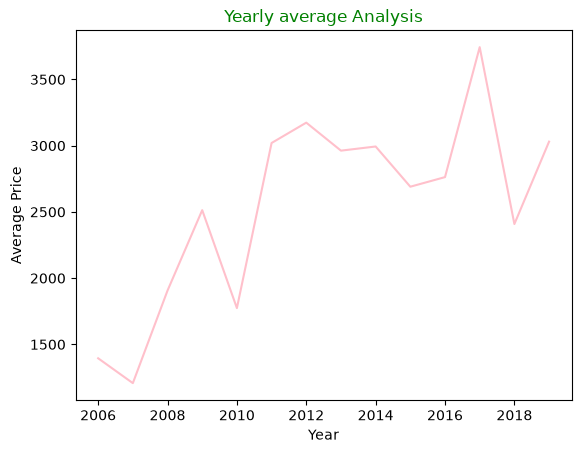

In [ ]:
# Plot the yearly average as a line chart with the price in KES on the y-axis.
# x axis = year
# y axis = avg_price_kes
plt.plot(yearly_avg["year"], yearly_avg["avg_price_kes"], color="pink")
plt.title("Yearly average Analysis", color = "green")
plt.xlabel("Year")
plt.ylabel("Average Price")
plt.show()


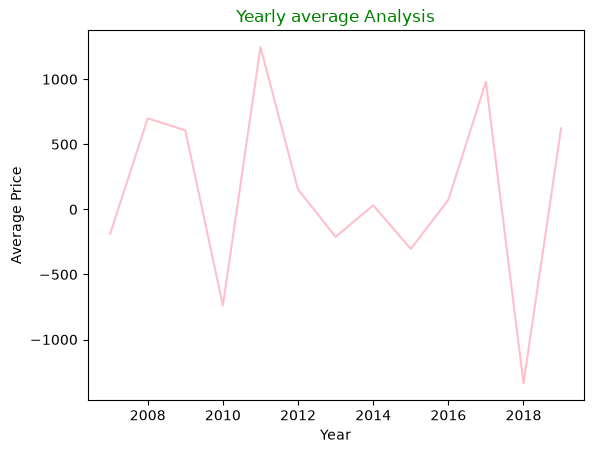

In [ ]:
plt.plot(yearly_avg["year"], yearly_avg["yoy_change_kes"], color="pink")
plt.title("Year over Year average Analysis", color = "green")
plt.xlabel("Year")
plt.ylabel("YOYPrice")
plt.show()